# 02 · 实验可信度诊断与平均处理效应

本页只读取统计产物和已生成图片，不重新执行检验、置换、模型训练或结果写入。正文及注释使用中文，表格使用英文标签并隐藏默认索引。

**阅读顺序：平均效果 → 分配比例 → 单变量平衡 → 联合可区分性 → 结果可学习性。** 每个表只回答一个问题，共用的范围、样本量和计算精度在表外说明一次。

In [1]:
# 选择已有实验结果：优先本地；设置 CRITEO_RESULTS_MODE=published 可只读公开快照。
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, HTML

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "criteo_uplift").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from criteo_uplift.pipeline_io import result_directory

RUN = result_directory("conversion_1000000_seed42", ROOT)
manifest = json.loads((RUN / "manifest.json").read_text())
print("结果来源：", RUN.relative_to(ROOT))
# 只定义展示样式，不计算统计量、不写入项目结果。
TABLE_STYLES = [
    {"selector": "", "props": [("border-collapse", "collapse"), ("font-size", "14px"), ("min-width", "640px")]},
    {"selector": "th", "props": [("background-color", "#edf3f8"), ("color", "#18364b"), ("padding", "10px 14px"), ("text-align", "right"), ("border-bottom", "2px solid #b9cddd")]},
    {"selector": "td", "props": [("padding", "9px 14px"), ("text-align", "right"), ("border-bottom", "1px solid #e3eaf0")]},
    {"selector": "tbody tr:nth-child(even)", "props": [("background-color", "#f7fafc")]},
    {"selector": "td:first-child, th:first-child", "props": [("text-align", "left")]},
]

结果来源： artifacts/conversion_1000000_seed42


## 1. 全量平均效果：差异有多大，区间有多宽？

读取 `ate_full.csv`。ATE 是处理组结果率减去对照组结果率；表中差值与区间采用百分点（pp），两组结果率及相对提升采用百分比。

这是全量公开样本的描述性实验背景，不用于模型选择。P 值按科学计数法展示；文件中的零值表示数值下溢，不表示真实概率为零。

Outcome,Control rate,Treatment rate,ATE (pp),95% CI (pp),Relative uplift,P-value
Conversion,0.1938%,0.3089%,+0.1152,"[+0.1085, +0.1219]",+59.45%,7.308e-179
Visit,3.8201%,4.8543%,+1.0342,"[+1.0056, +1.0629]",+27.07%,0.000e+00


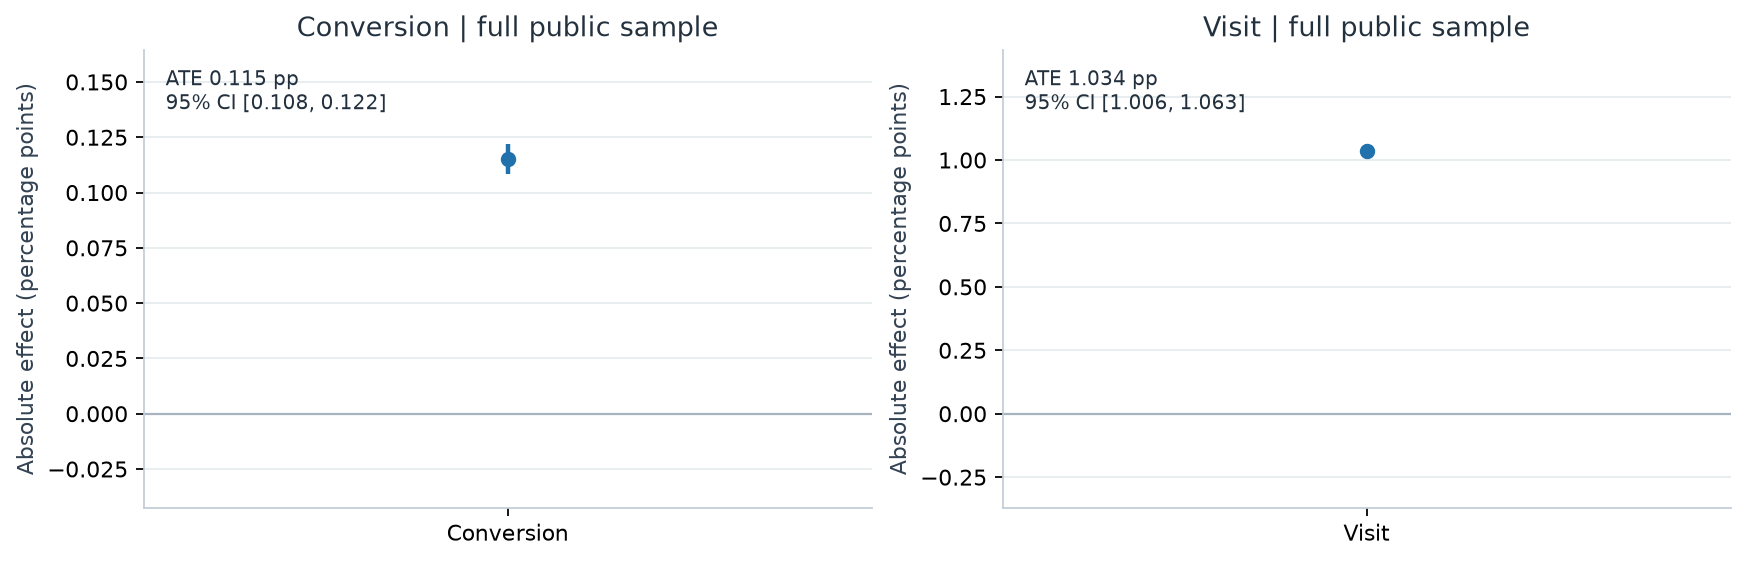

In [2]:
# 只转换显示单位并格式化，原始结果表保持不变。
ate = pd.read_csv(RUN / "diagnostics/ate_full.csv")
ate_table = pd.DataFrame({
    "Outcome": ate["outcome"].str.capitalize(),
    "Control rate": ate["response_control"], "Treatment rate": ate["response_treatment"],
    "ATE (pp)": ate["ate"] * 100,
    "95% CI (pp)": [f"[{lo * 100:+.4f}, {hi * 100:+.4f}]" for lo, hi in zip(ate["ci_low"], ate["ci_high"])],
    "Relative uplift": ate["relative_uplift"], "P-value": ate["p_value"],
})
display(ate_table.style.hide(axis="index").format({
    "Control rate": "{:.4%}", "Treatment rate": "{:.4%}", "ATE (pp)": "{:+.4f}",
    "Relative uplift": "{:+.2%}", "P-value": "{:.3e}",
}, na_rep="—").set_table_styles(TABLE_STYLES).set_properties(subset=["95% CI (pp)"], **{"white-space": "nowrap"}))
# 图像由报告生成阶段保存，不在此重新绘制。
display(Image(filename=str(RUN / "figures/ate_full.png")))

## 2. 分配比例：公开计数是否接近外部参考？

读取 `srm.json`。85% 是发布数据的外部参考比例，并非已知的原始实验设计参数。这里的显著或不显著均不能直接证明原始线上实验是否通过 SRM 或随机化。

In [3]:
# 样本量与范围只说明一次，表内聚焦观测比例、参考比例与检验结果。
srm = json.loads((RUN / "diagnostics/srm.json").read_text())
print(f"分析范围：全量公开数据｜Control：{srm['n_control']:,} 行｜Treatment：{srm['n_treatment']:,} 行")
srm_table = pd.DataFrame([srm])[["observed_ratio", "expected_ratio", "chi2", "pvalue", "status"]].rename(columns={
    "observed_ratio": "Observed treatment share", "expected_ratio": "Reference share",
    "chi2": "Chi-square", "pvalue": "P-value", "status": "Status",
})
display(srm_table.style.hide(axis="index").format({
    "Observed treatment share": "{:.6%}", "Reference share": "{:.2%}", "Chi-square": "{:.3e}", "P-value": "{:.3e}",
}, na_rep="—").set_table_styles(TABLE_STYLES))
print("参考资料：", srm["reference_source"])

分析范围：全量公开数据｜Control：2,096,937 行｜Treatment：11,882,655 行


Observed treatment share,Reference share,Chi-square,P-value,Status
85.000013%,85.00%,1.818e-06,9.989e-01,computed


参考资料： https://arxiv.org/html/2111.10106#S3


## 3. 单变量平衡：哪些特征存在分布差异？

读取 `balance.csv`；范围与上节相同，使用原始 CSV 的 `float64` 表示。样本量、范围、精度和指纹不再逐特征重复列出。

表格按已保存的 `|SMD|` 排序，只保留两组均值、带方向的 SMD、KS 的 **D 统计量**及辅助 P 值。D 是经验分布函数的最大距离，不是乘以根号样本量后的量。大样本下优先看差异大小；KS P 值未经多重校正，不能仅凭显著性判定实际重要性。

In [4]:
# 选取与特征直接相关的列；排序只改变展示顺序，不重新计算统计量。
balance = pd.read_csv(RUN / "diagnostics/balance.csv")
balance_table = balance.sort_values("abs_smd", ascending=False)[[
    "feature", "mean_control", "mean_treatment", "smd", "ks_statistic", "ks_pvalue",
]].rename(columns={
    "feature": "Feature", "mean_control": "Control mean", "mean_treatment": "Treatment mean",
    "smd": "SMD", "ks_statistic": "KS D", "ks_pvalue": "KS P-value",
})
display(balance_table.style.hide(axis="index").format({
    "Control mean": "{:.5f}", "Treatment mean": "{:.5f}", "SMD": "{:+.6f}", "KS D": "{:.6f}", "KS P-value": "{:.3e}",
}, na_rep="—").set_table_styles(TABLE_STYLES).set_properties(subset=["SMD", "KS D"], **{"font-weight": "600", "color": "#175c83"}))

Feature,Control mean,Treatment mean,SMD,KS D,KS P-value
f3,4.23282,4.16941,-0.048836,0.013794,5.007e-295
f6,-3.99988,-4.18279,-0.040448,0.013069,7.419e-265
f5,4.03934,4.02660,-0.030557,0.006099,5.198e-58
f9,15.88625,16.05259,+0.024001,0.007125,5.184e-79
f1,10.06794,10.07034,+0.023994,0.002662,2.119e-11
f8,3.93465,3.93339,-0.022433,0.008334,5.837e-108
f7,5.08028,5.10556,+0.021270,0.006099,5.198e-58
f10,5.33190,5.33366,+0.010563,0.002415,1.882e-09
f4,10.33653,10.33925,+0.007966,0.002412,1.959e-09
f0,19.65170,19.61476,-0.006866,0.008950,1.913e-124


## 4. 联合可区分性：模型能否区分两组？

C2ST 从全量来源按组等概率无放回抽样，构造两组等量的诊断样本；它不等于建模样本，也不使用正式测试集选模。

内部训练／留出各自置换 treatment，并完整重拟合固定分类器。关注留出 AUC 与 Holm 校正后的 P 值：AUC 的随机基准为 0.5；不显著不证明联合分布相同，显著也不能单独证明随机化失败。

诊断样本：Control 10,000 行 + Treatment 10,000 行；内部训练／留出为 70%／30%。
随机种子：42｜完整重拟合置换：499 次｜P 值分辨率：0.0020｜两模型 Holm 校正。


Model,Holdout ROC AUC,Permutation P-value,Holm P-value
logistic,0.5177,0.006,0.012
hgb,0.5101,0.076,0.076


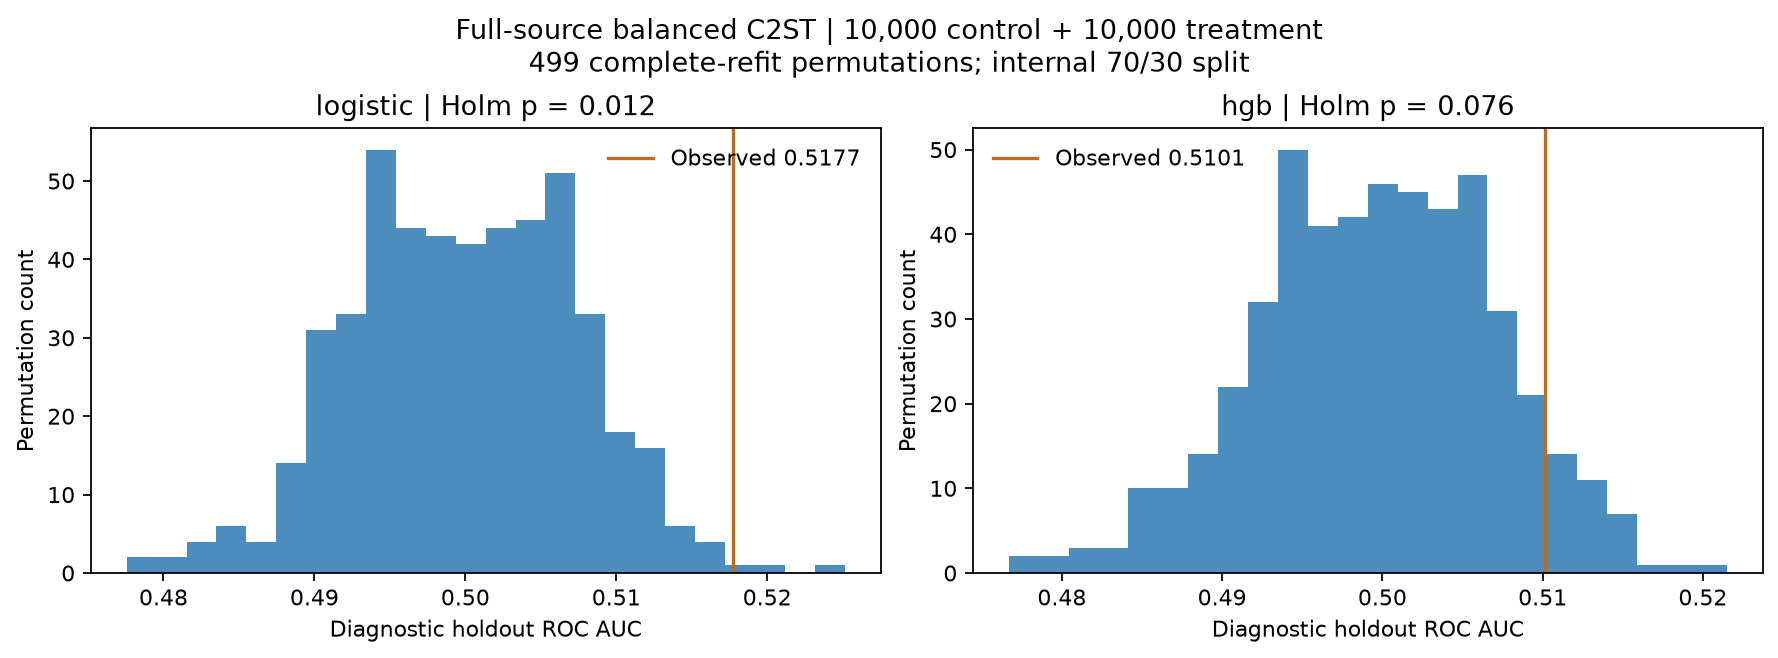

In [5]:
# 共用的抽样与置换配置只在表外展示；表内每行只保留模型自身结果。
c2st = pd.read_csv(RUN / "diagnostics/c2st.csv")
details = json.loads((RUN / "diagnostics/c2st_details.json").read_text())
print(f"诊断样本：Control {details['n_control']:,} 行 + Treatment {details['n_treatment']:,} 行；内部训练／留出为 70%／30%。")
print(f"随机种子：{details['seed']}｜完整重拟合置换：{details['permutations']:,} 次｜P 值分辨率：{details['pvalue_resolution']:.4f}｜两模型 Holm 校正。")
c2st_table = c2st[["model", "roc_auc", "pvalue", "pvalue_holm"]].rename(columns={
    "model": "Model", "roc_auc": "Holdout ROC AUC", "pvalue": "Permutation P-value", "pvalue_holm": "Holm P-value",
})
display(c2st_table.style.hide(axis="index").format({
    "Holdout ROC AUC": "{:.4f}", "Permutation P-value": "{:.3f}", "Holm P-value": "{:.3f}",
}, na_rep="—").set_table_styles(TABLE_STYLES))
# 已有零分布图直接读取；旧实验缺图时不会启动置换或绘图。
null_plot = RUN / "figures/c2st_null.png"
if null_plot.is_file():
    display(Image(filename=str(null_plot)))
else:
    print("该实验未保存置换分布图；表格中的已有检验结果仍可阅读。")

## 5. 结果可学习性：特征能预测结果吗？

读取 `learnability.csv`，默认查看整个训练／验证集范围（`whole`），按结果指标分别比较 Dummy 与固定模型。可修改下方 `LEARNING_SCOPE` 以查看某个已保存的分组，选项以输出提示为准。

ROC AUC／AP 越高越好，Log loss／Brier 越低越好；AP 应结合验证集正例率阅读。结果可预测不等于 CATE 可预测，也不能代替策略增量评价。

In [6]:
# 仅筛选已有范围与结果；各模型共用的样本量和正例率在表外展示。
LEARNING_SCOPE = "whole"
learning = pd.read_csv(RUN / "diagnostics/learnability.csv")
print("已保存的分析范围：", ", ".join(learning["scope"].unique()))
learning_view = learning.loc[learning["scope"] == LEARNING_SCOPE]
if learning_view.empty:
    print("该结果文件没有所选范围，请从上面的范围中选择。")
for outcome in learning_view["outcome"].unique():
    rows = learning_view.loc[learning_view["outcome"] == outcome]
    context = rows.iloc[0]
    print(f"分析指标：{outcome}｜范围：{LEARNING_SCOPE}｜训练 {context['n_train']:,} 行，验证 {context['n_validation']:,} 行")
    print(f"正例率：训练 {context['positive_rate_train']:.4%}，验证 {context['positive_rate_validation']:.4%}")
    table = rows[["model", "roc_auc", "average_precision", "log_loss", "brier", "status"]].rename(columns={
        "model": "Model", "roc_auc": "ROC AUC", "average_precision": "AP", "log_loss": "Log loss", "brier": "Brier", "status": "Status",
    })
    display(table.style.hide(axis="index").format({
        "ROC AUC": "{:.4f}", "AP": "{:.4f}", "Log loss": "{:.5f}", "Brier": "{:.5f}",
    }, na_rep="—").set_table_styles(TABLE_STYLES))

已保存的分析范围： whole, treatment, control
分析指标：visit｜范围：whole｜训练 600,000 行，验证 200,000 行
正例率：训练 4.6762%，验证 4.6870%


Model,ROC AUC,AP,Log loss,Brier,Status
dummy,0.5000,0.0469,0.18919,0.04467,computed
logistic,0.9320,0.4785,0.11161,0.03141,computed
hgb,0.9442,0.5041,0.10515,0.03013,computed


分析指标：conversion｜范围：whole｜训练 600,000 行，验证 200,000 行
正例率：训练 0.2882%，验证 0.2880%


Model,ROC AUC,AP,Log loss,Brier,Status
dummy,0.5000,0.0029,0.01972,0.00287,computed
logistic,0.9460,0.1926,0.01264,0.00258,computed
hgb,0.9509,0.2260,0.01205,0.00250,computed


## 解释边界与刷新方式

这些诊断不证明用户级独立、特征生成时点有效、随机化成立或真实投放收益。公开数据经过发布处理，未知用户依赖、实验分块与跨实验结构仍属于限制。不要根据这些已查看的结果反复调整测试集或正式模型选择。

本页不自动生成“通过／失败”的统计结论，也不重复打印前面各表的数据。要重新运行诊断，应在终端明确执行主流程的 `--diagnostics-only` 模式；这会改写相应诊断产物，与重新运行本页展示单元格不同。详见 [项目流程](../docs/PROJECT_PIPELINE.md)。